<a href="https://colab.research.google.com/github/dylanong4/University-ML-classification-project/blob/main/MAS3919_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import numpy as np
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target

(569, 30)
(569,)
{np.int64(0): np.int64(212), np.int64(1): np.int64(357)}
target names: ['malignant' 'benign']


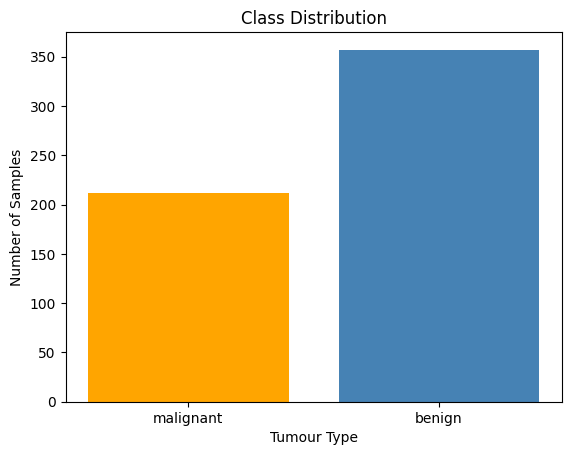

In [ ]:
#shape of x and y
print(X.shape)
print(y.shape)

#no. samples per class
unique, counts = np.unique(y, return_counts=True)
print(dict(zip(unique, counts)))

#meaning of class labels
print("target names:", data.target_names)

#class distribution plot
plt.bar(data.target_names, counts, color=['orange', 'steelblue'])
plt.title("Class Distribution")
plt.xlabel("Tumour Type")
plt.ylabel("Number of Samples")

plt.savefig("class_distribution.pdf", bbox_inches="tight")

plt.show()

In [ ]:
#task 2 - train/test split

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,    #80/20
    random_state=42,
    stratify = y       #keep class frequency balanced
)

#standardise features by scaling on training data

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#convert to tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

#check shape
print(f"\nX_train shape: {X_train_tensor.shape}")
print(f"X_test shape:  {X_test_tensor.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")


X_train shape: torch.Size([455, 30])
X_test shape:  torch.Size([114, 30])
y_train shape: torch.Size([455])
y_test shape:  torch.Size([114])


In [ ]:
#task 3 - neural network

import torch.nn as nn

class Net(nn.Module):

    def __init__(self, input_dim=30):
        super(Net, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),   # hidden layer 1
            nn.ReLU(),
            nn.Linear(64, 32),          # hidden layer 2
            nn.ReLU(),
            nn.Linear(32, 1),           # output layer
            nn.Sigmoid()                # squash output to (0, 1) probability
        )

    def forward(self, x):
        return self.network(x)


#inspect the model
model = Net(input_dim=X_train.shape[1])
print(model)

# total trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params}")

# Quick sanity check — pass one sample through
with torch.no_grad():
    sample_output = model(X_train_tensor[:1])
    print(f"Sample output (probability): {sample_output.item():.4f}")

Net(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)

Total trainable parameters: 4097
Sample output (probability): 0.4488


Net(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
Epoch 0, Train Loss: 0.7127, Test Loss: 0.7013
Epoch 10, Train Loss: 0.6043, Test Loss: 0.5981
Epoch 20, Train Loss: 0.4715, Test Loss: 0.4715
Epoch 30, Train Loss: 0.3211, Test Loss: 0.3337
Epoch 40, Train Loss: 0.2044, Test Loss: 0.2286
Epoch 50, Train Loss: 0.1385, Test Loss: 0.1665


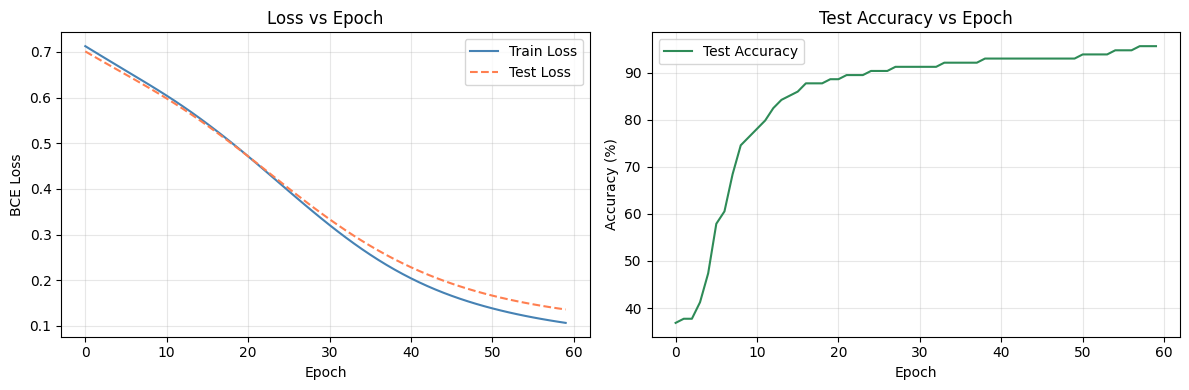


Final Test Accuracy: 95.61%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

#task 4 - loss function and optimiser

set_seed(42)

model = Net(input_dim=X_train.shape[1])

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

#task 5 - train model

num_epochs = 60

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train.unsqueeze(1))
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # eval
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test.unsqueeze(1))
        test_losses.append(test_loss.item())

        predicted = (test_outputs > 0.5).float()
        correct = (predicted == y_test.unsqueeze(1)).float().sum()
        accuracy = correct / y_test.numel()
        test_accuracies.append(accuracy.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

epochs = range(num_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, train_losses, label="Train Loss", color="steelblue")
axes[0].plot(epochs, test_losses,  label="Test Loss",  color="coral", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss vs Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(epochs, [a * 100 for a in test_accuracies],
             label="Test Accuracy", color="seagreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Test Accuracy vs Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.pdf", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFinal Test Accuracy: {test_accuracies[-1]*100:.2f}%")

Test Accuracy: 95.61%
Precision:     0.9718
Recall:        0.9583
F1-Score:      0.9650

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



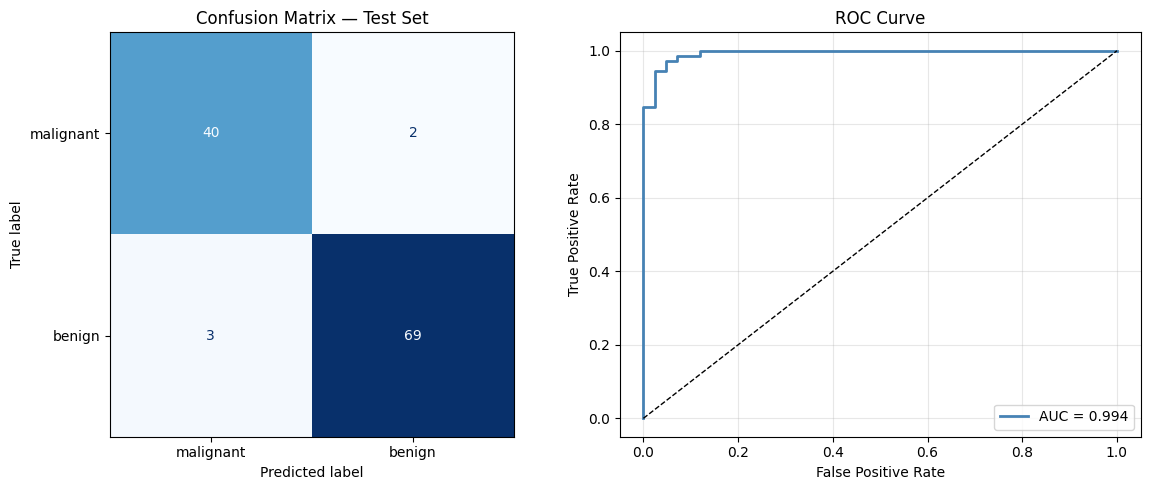

In [ ]:
# task 6 - model evaluation

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt


model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    # Convert probabilities to numpy for ROC curve and binarize for other metrics
    y_prob = test_outputs.squeeze().numpy()
    predicted = (test_outputs > 0.5).float()

y_true = y_test.numpy()
y_pred = predicted.squeeze().numpy()

# performance metrics
accuracy  = (y_pred == y_true).mean()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}")
print(f"F1-Score:      {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cf, display_labels=data.target_names)
disp.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — Test Set")

# ROC curve
ax_roc = axes[1]
fpr, tpr, _ = roc_curve(y_test.numpy(), y_prob) # y_test is a tensor, convert to numpy
roc_auc     = auc(fpr, tpr)
ax_roc.plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect both plots
plt.show()

Test Accuracy: 98.25%
Precision:     0.9861
Recall:        0.9861
F1-Score:      0.9861

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

Logistic Regression Test Accuracy: 98.25%
Neural Network Test Accuracy:      95.61%
Difference:                        -2.63%

Logistic Regression Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



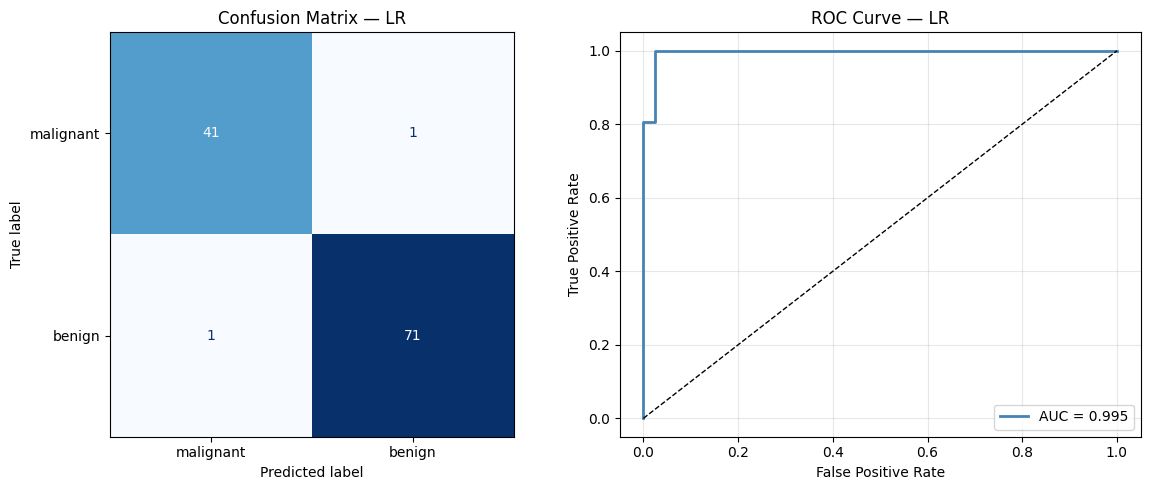

In [ ]:
#baseline logistic regresssion


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt # Ensure matplotlib is imported for plotting

#tensors to numpy for sklearn
X_train_np = X_train_tensor.numpy()
X_test_np  = X_test_tensor.numpy()
y_train_np = y_train.numpy()
y_test_np  = y_test.numpy()

set_seed(42)

# Train logistic regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_np, y_train_np)

# Evaluate on test set
y_pred_lr = log_reg.predict(X_test_np)
y_prob_lr = log_reg.predict_proba(X_test_np)[:, 1] # Get probabilities for ROC curve

# performance metrics
accuracy_lr  = accuracy_score(y_test_np, y_pred_lr)
precision_lr = precision_score(y_test_np, y_pred_lr)
recall_lr    = recall_score(y_test_np, y_pred_lr)
f1_lr        = f1_score(y_test_np, y_pred_lr)

print(f"Test Accuracy: {accuracy_lr * 100:.2f}%")
print(f"Precision:     {precision_lr:.4f}")
print(f"Recall:        {recall_lr:.4f}")
print(f"F1-Score:      {f1_lr:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

print(f"Logistic Regression Test Accuracy: {accuracy_lr * 100:.2f}%")
print(f"Neural Network Test Accuracy:      {test_accuracies[-1] * 100:.2f}%")
print(f"Difference:                        {(test_accuracies[-1] - accuracy_lr) * 100:.2f}%")

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test_np, y_pred_lr, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf_lr = confusion_matrix(y_test_np, y_pred_lr) # Use y_test_np and y_pred_lr for LR
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cf_lr, display_labels=data.target_names)
disp_lr.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — LR")

# ROC curve
ax_roc = axes[1]
fpr_lr, tpr_lr, _ = roc_curve(y_test_np, y_prob_lr) # Use y_test_np and y_prob_lr for LR
roc_auc_lr     = auc(fpr_lr, tpr_lr)
ax_roc.plot(fpr_lr, tpr_lr, color="steelblue", lw=2, label=f"AUC = {roc_auc_lr:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve — LR")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("logistic_regression_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect LR plots
plt.show()

Net(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
Epoch 0, Train Loss: 0.7127, Test Loss: 0.7013
Epoch 10, Train Loss: 0.6043, Test Loss: 0.5981
Epoch 20, Train Loss: 0.4715, Test Loss: 0.4715
Epoch 30, Train Loss: 0.3211, Test Loss: 0.3337
Epoch 40, Train Loss: 0.2044, Test Loss: 0.2286
Epoch 50, Train Loss: 0.1385, Test Loss: 0.1665
Epoch 60, Train Loss: 0.1042, Test Loss: 0.1337
Epoch 70, Train Loss: 0.0849, Test Loss: 0.1160
Epoch 80, Train Loss: 0.0728, Test Loss: 0.1051
Epoch 90, Train Loss: 0.0641, Test Loss: 0.0978
Epoch 100, Train Loss: 0.0575, Test Loss: 0.0932
Epoch 110, Train Loss: 0.0521, Test Loss: 0.0909
Epoch 120, Train Loss: 0.0477, Test Loss: 0.0895
Epoch 130, Train Loss: 0.0439, Test Loss: 0.0882
Epoch 140, Train Loss: 0.0407, Test Loss: 0.0870
Epoch 150,

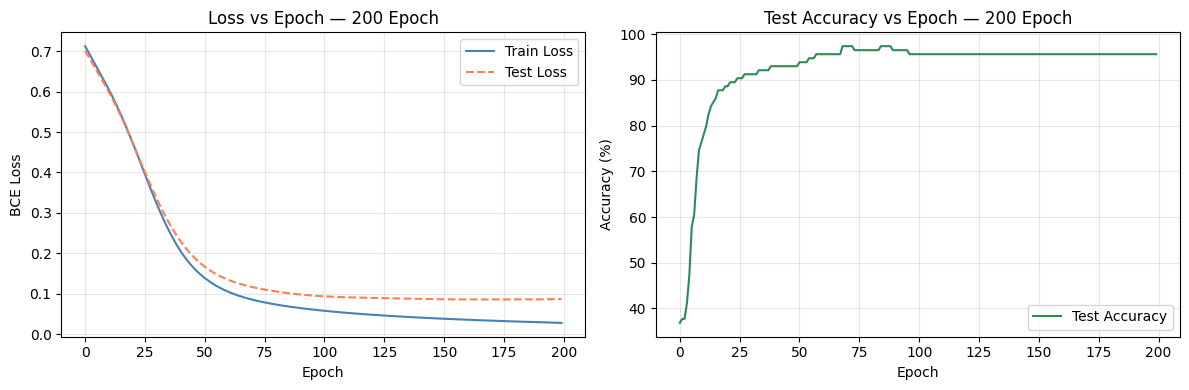


Final Test Accuracy — 200 Epoch: 95.61%
Test Accuracy — 200 Epoch: 95.61%
Precision — 200 Epoch:     0.9855
Recall — 200 Epoch:        0.9444
F1-Score — 200 Epoch:      0.9645

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



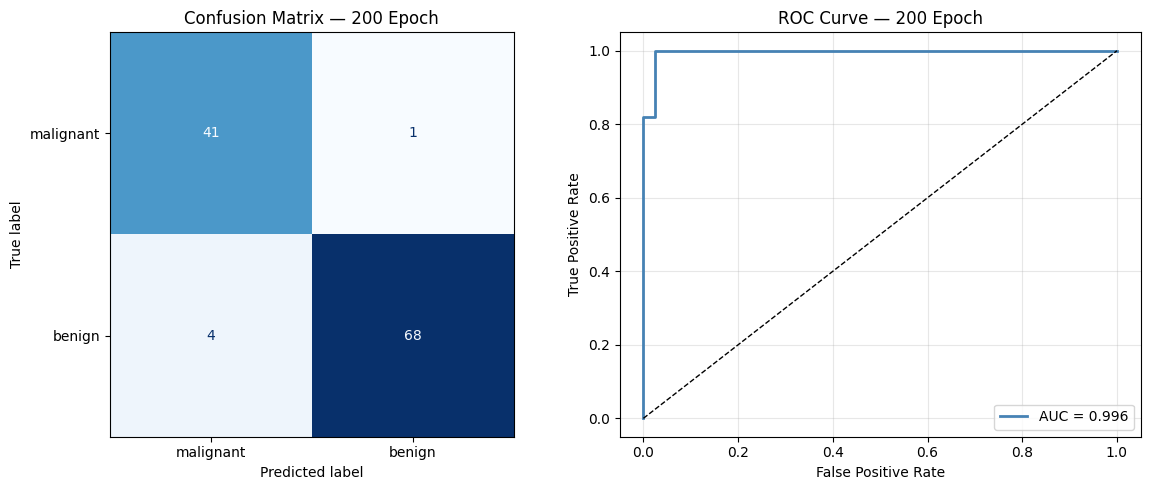

In [ ]:
#model experiment 1 - change epoch to 200

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

#task 4

set_seed(42)

model = Net(input_dim=X_train.shape[1])

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

#task 5

num_epochs = 200

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train.unsqueeze(1))
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # eval
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test.unsqueeze(1))
        test_losses.append(test_loss.item())

        predicted = (test_outputs > 0.5).float()
        correct = (predicted == y_test.unsqueeze(1)).float().sum()
        accuracy = correct / y_test.numel()
        test_accuracies.append(accuracy.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

epochs = range(num_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, train_losses, label="Train Loss", color="steelblue")
axes[0].plot(epochs, test_losses,  label="Test Loss",  color="coral", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss vs Epoch — 200 Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(epochs, [a * 100 for a in test_accuracies],
             label="Test Accuracy", color="seagreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Test Accuracy vs Epoch — 200 Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFinal Test Accuracy — 200 Epoch: {test_accuracies[-1]*100:.2f}%")

# task 6 - model evaluation

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt


model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    # Convert probabilities to numpy for ROC curve and binarize for other metrics
    y_prob = test_outputs.squeeze().numpy()
    predicted = (test_outputs > 0.5).float()

y_true = y_test.numpy()
y_pred = predicted.squeeze().numpy()

# performance metrics
accuracy  = (y_pred == y_true).mean()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Test Accuracy — 200 Epoch: {accuracy * 100:.2f}%")
print(f"Precision — 200 Epoch:     {precision:.4f}")
print(f"Recall — 200 Epoch:        {recall:.4f}")
print(f"F1-Score — 200 Epoch:      {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cf, display_labels=data.target_names)
disp.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — 200 Epoch")

# ROC curve
ax_roc = axes[1]
fpr, tpr, _ = roc_curve(y_test.numpy(), y_prob) # y_test is a tensor, convert to numpy
roc_auc     = auc(fpr, tpr)
ax_roc.plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve — 200 Epoch")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect both plots
plt.show()

NetWithDropout(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
    (7): Sigmoid()
  )
)
Epoch 0, Train Loss: 0.7098, Test Loss: 0.7014
Epoch 10, Train Loss: 0.6137, Test Loss: 0.6000
Epoch 20, Train Loss: 0.4831, Test Loss: 0.4747
Epoch 30, Train Loss: 0.3384, Test Loss: 0.3372
Epoch 40, Train Loss: 0.2178, Test Loss: 0.2315
Epoch 50, Train Loss: 0.1623, Test Loss: 0.1678


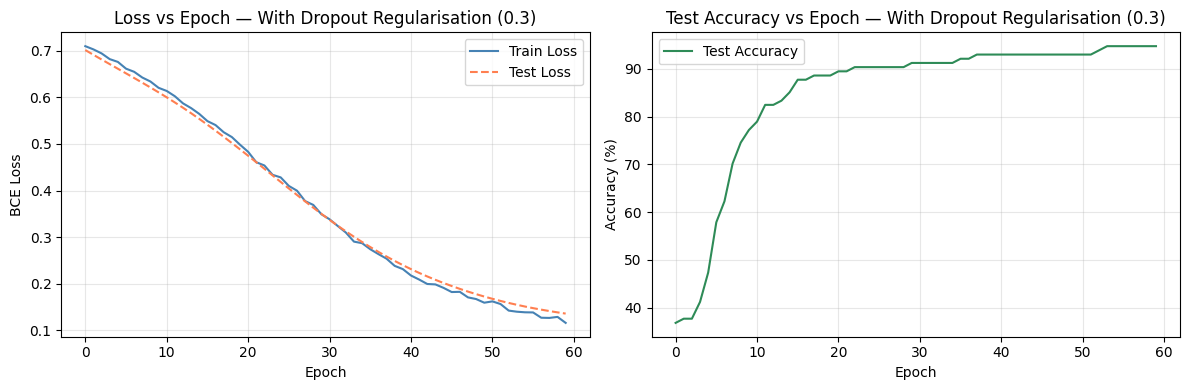


Final Test Accuracy: 94.74%
Test Accuracy — With Dropout Regularisation (0.3): 94.74%
Precision — With Dropout Regularisation (0.3):     0.9583
Recall — With Dropout Regularisation (0.3):        0.9583
F1-Score — With Dropout Regularisation (0.3):      0.9583

Classification Report - With Dropout Regularisation:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



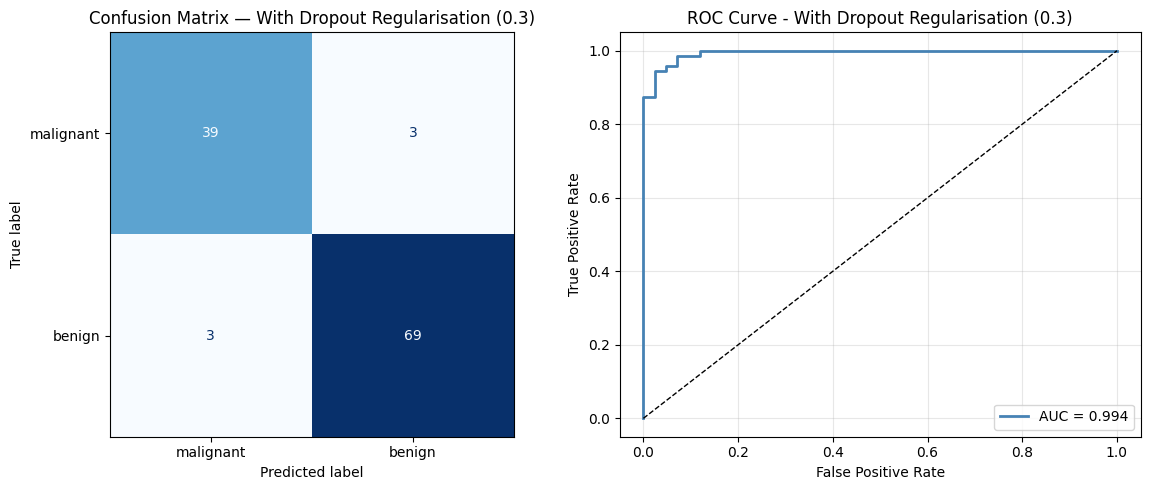

In [ ]:
#model experiment 2, full nn pipeline - add dropout regularisation (50 epoch, drop out rate = 0.3)

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

set_seed(42)

class NetWithDropout(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),   # ← add after activations
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x)

#task 4 - loss function and optimiser

model = model = NetWithDropout(input_dim=X_train.shape[1], dropout_rate=0.3)

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

#task 5 - train model

num_epochs = 60

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train.unsqueeze(1))
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # eval
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test.unsqueeze(1))
        test_losses.append(test_loss.item())

        predicted = (test_outputs > 0.5).float()
        correct = (predicted == y_test.unsqueeze(1)).float().sum()
        accuracy = correct / y_test.numel()
        test_accuracies.append(accuracy.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

epochs = range(num_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, train_losses, label="Train Loss", color="steelblue")
axes[0].plot(epochs, test_losses,  label="Test Loss",  color="coral", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss vs Epoch — With Dropout Regularisation (0.3)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(epochs, [a * 100 for a in test_accuracies],
             label="Test Accuracy", color="seagreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Test Accuracy vs Epoch — With Dropout Regularisation (0.3)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFinal Test Accuracy: {test_accuracies[-1]*100:.2f}%")

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt


model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    # Convert probabilities to numpy for ROC curve and binarize for other metrics
    y_prob = test_outputs.squeeze().numpy()
    predicted = (test_outputs > 0.5).float()

y_true = y_test.numpy()
y_pred = predicted.squeeze().numpy()

# performance metrics
accuracy  = (y_pred == y_true).mean()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Test Accuracy — With Dropout Regularisation (0.3): {accuracy * 100:.2f}%")
print(f"Precision — With Dropout Regularisation (0.3):     {precision:.4f}")
print(f"Recall — With Dropout Regularisation (0.3):        {recall:.4f}")
print(f"F1-Score — With Dropout Regularisation (0.3):      {f1:.4f}")

print("\nClassification Report - With Dropout Regularisation:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cf, display_labels=data.target_names)
disp.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — With Dropout Regularisation (0.3)")

# ROC curve
ax_roc = axes[1]
fpr, tpr, _ = roc_curve(y_test.numpy(), y_prob) # y_test is a tensor, convert to numpy
roc_auc     = auc(fpr, tpr)
ax_roc.plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve - With Dropout Regularisation (0.3)")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect both plots
plt.show()

NetWithDropout(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
    (7): Sigmoid()
  )
)
Epoch 0, Train Loss: 0.7109, Test Loss: 0.7013
Epoch 10, Train Loss: 0.6121, Test Loss: 0.5992
Epoch 20, Train Loss: 0.4818, Test Loss: 0.4729
Epoch 30, Train Loss: 0.3291, Test Loss: 0.3351
Epoch 40, Train Loss: 0.2133, Test Loss: 0.2296
Epoch 50, Train Loss: 0.1528, Test Loss: 0.1666


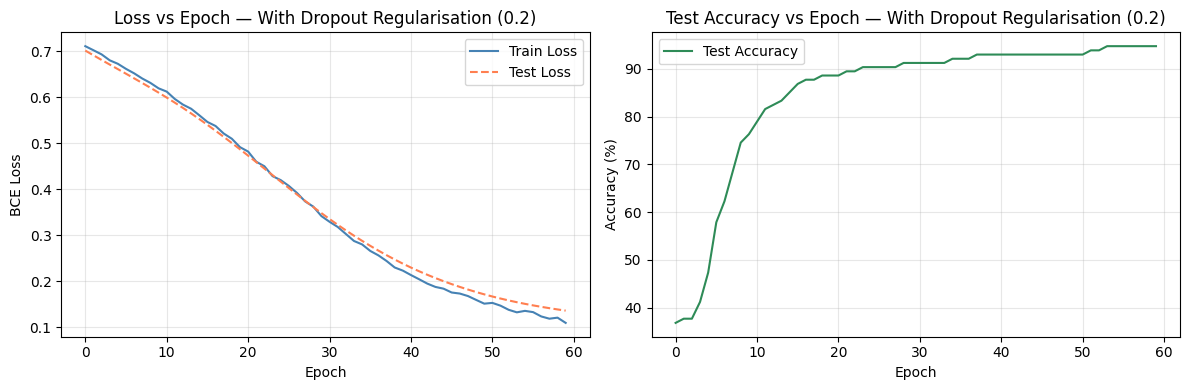


Final Test Accuracy: 94.74%
Test Accuracy — With Dropout Regularisation (0.2): 94.74%
Precision — With Dropout Regularisation (0.2):     0.9583
Recall — With Dropout Regularisation (0.2):        0.9583
F1-Score — With Dropout Regularisation (0.2):      0.9583

Classification Report - With Dropout Regularisation:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



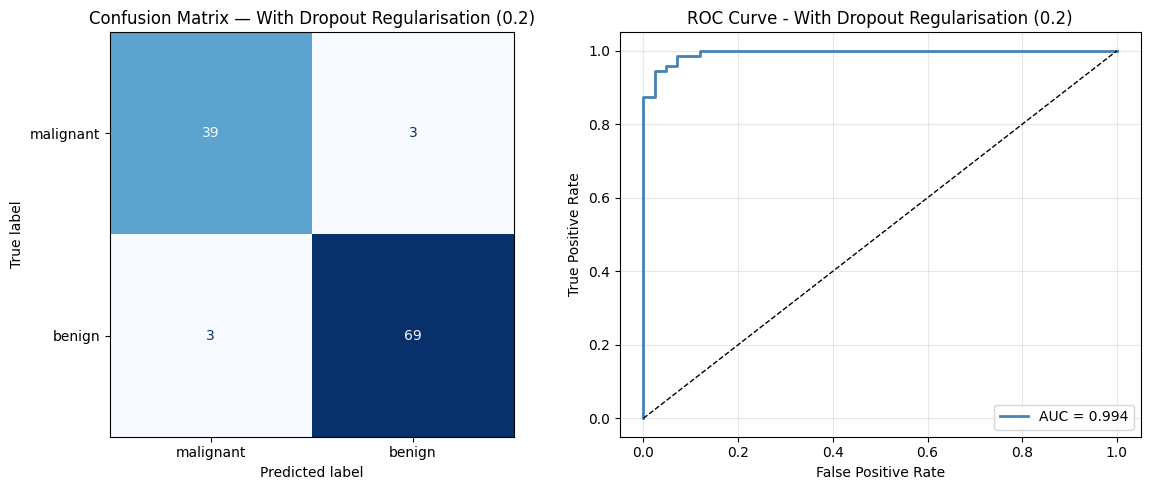

In [ ]:
#model experiment 2, full nn pipeline - add dropout regularisation (50 epoch, drop out rate = 0.2)

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

set_seed(42)

class NetWithDropout(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),   # ← add after activations
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x)

#task 4 - loss function and optimiser

model = model = NetWithDropout(input_dim=X_train.shape[1], dropout_rate=0.2)

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

#task 5 - train model

num_epochs = 60

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train.unsqueeze(1))
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # eval
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test.unsqueeze(1))
        test_losses.append(test_loss.item())

        predicted = (test_outputs > 0.5).float()
        correct = (predicted == y_test.unsqueeze(1)).float().sum()
        accuracy = correct / y_test.numel()
        test_accuracies.append(accuracy.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

epochs = range(num_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, train_losses, label="Train Loss", color="steelblue")
axes[0].plot(epochs, test_losses,  label="Test Loss",  color="coral", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss vs Epoch — With Dropout Regularisation (0.2)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(epochs, [a * 100 for a in test_accuracies],
             label="Test Accuracy", color="seagreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Test Accuracy vs Epoch — With Dropout Regularisation (0.2)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFinal Test Accuracy: {test_accuracies[-1]*100:.2f}%")

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt


model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    # Convert probabilities to numpy for ROC curve and binarize for other metrics
    y_prob = test_outputs.squeeze().numpy()
    predicted = (test_outputs > 0.5).float()

y_true = y_test.numpy()
y_pred = predicted.squeeze().numpy()

# performance metrics
accuracy  = (y_pred == y_true).mean()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Test Accuracy — With Dropout Regularisation (0.2): {accuracy * 100:.2f}%")
print(f"Precision — With Dropout Regularisation (0.2):     {precision:.4f}")
print(f"Recall — With Dropout Regularisation (0.2):        {recall:.4f}")
print(f"F1-Score — With Dropout Regularisation (0.2):      {f1:.4f}")

print("\nClassification Report - With Dropout Regularisation:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cf, display_labels=data.target_names)
disp.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — With Dropout Regularisation (0.2)")

# ROC curve
ax_roc = axes[1]
fpr, tpr, _ = roc_curve(y_test.numpy(), y_prob) # y_test is a tensor, convert to numpy
roc_auc     = auc(fpr, tpr)
ax_roc.plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve - With Dropout Regularisation (0.2)")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect both plots
plt.show()

NetWithDropout(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
    (7): Sigmoid()
  )
)
Epoch 0, Train Loss: 0.7121, Test Loss: 0.7013
Epoch 10, Train Loss: 0.6063, Test Loss: 0.5981
Epoch 20, Train Loss: 0.4774, Test Loss: 0.4713
Epoch 30, Train Loss: 0.3220, Test Loss: 0.3335
Epoch 40, Train Loss: 0.2098, Test Loss: 0.2281
Epoch 50, Train Loss: 0.1443, Test Loss: 0.1659


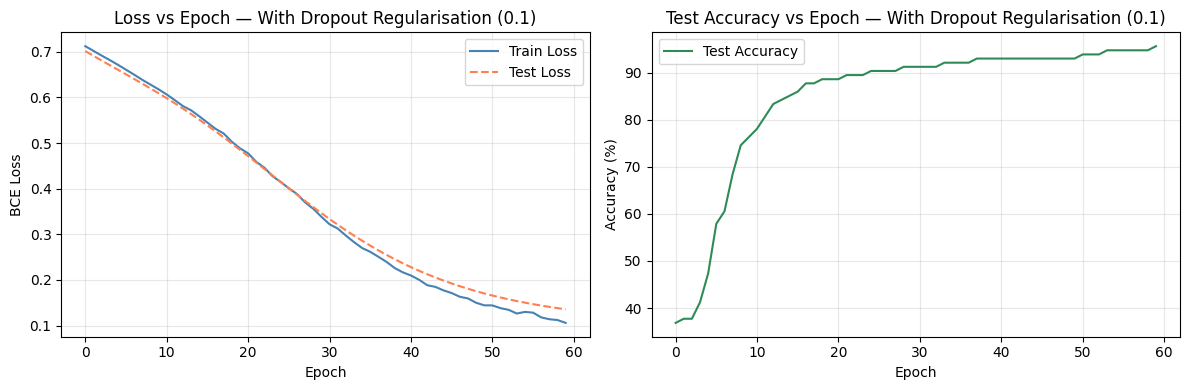


Final Test Accuracy: 95.61%
Test Accuracy — With Dropout Regularisation (0.1): 95.61%
Precision — With Dropout Regularisation (0.1):     0.9718
Recall — With Dropout Regularisation (0.1):        0.9583
F1-Score — With Dropout Regularisation (0.1):      0.9650

Classification Report - With Dropout Regularisation:
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



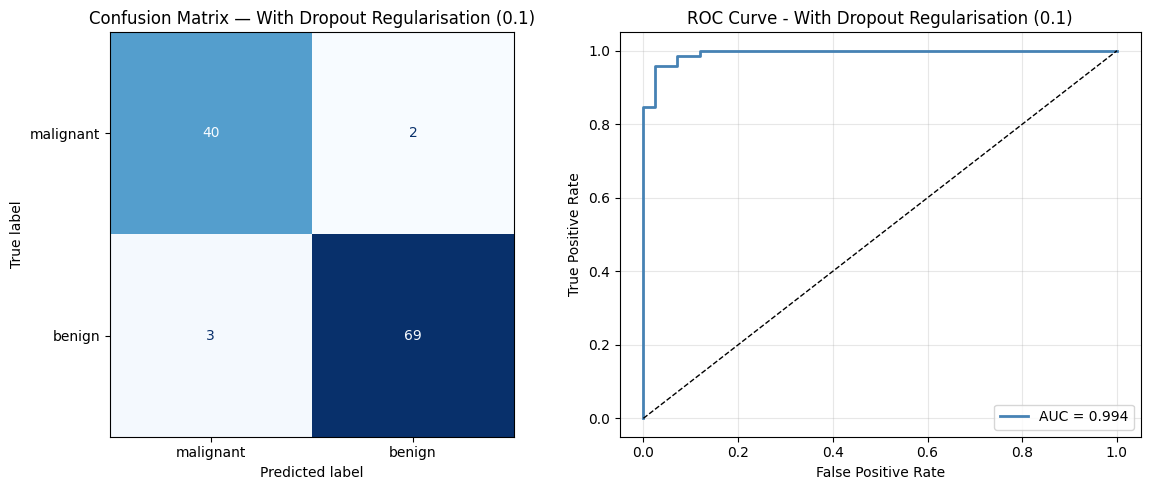

In [ ]:
#model experiment 2, full nn pipeline - add dropout regularisation (50 epoch, drop out rate = 0.1)

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

set_seed(42)

class NetWithDropout(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.1):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),   # ← add after activations
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x)

#task 4 - loss function and optimiser

model = model = NetWithDropout(input_dim=X_train.shape[1], dropout_rate=0.1)

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

#task 5 - train model

num_epochs = 60

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train.unsqueeze(1))
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # eval
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test.unsqueeze(1))
        test_losses.append(test_loss.item())

        predicted = (test_outputs > 0.5).float()
        correct = (predicted == y_test.unsqueeze(1)).float().sum()
        accuracy = correct / y_test.numel()
        test_accuracies.append(accuracy.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

epochs = range(num_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, train_losses, label="Train Loss", color="steelblue")
axes[0].plot(epochs, test_losses,  label="Test Loss",  color="coral", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss vs Epoch — With Dropout Regularisation (0.1)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(epochs, [a * 100 for a in test_accuracies],
             label="Test Accuracy", color="seagreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Test Accuracy vs Epoch — With Dropout Regularisation (0.1)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFinal Test Accuracy: {test_accuracies[-1]*100:.2f}%")

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt


model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    # Convert probabilities to numpy for ROC curve and binarize for other metrics
    y_prob = test_outputs.squeeze().numpy()
    predicted = (test_outputs > 0.5).float()

y_true = y_test.numpy()
y_pred = predicted.squeeze().numpy()

# performance metrics
accuracy  = (y_pred == y_true).mean()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Test Accuracy — With Dropout Regularisation (0.1): {accuracy * 100:.2f}%")
print(f"Precision — With Dropout Regularisation (0.1):     {precision:.4f}")
print(f"Recall — With Dropout Regularisation (0.1):        {recall:.4f}")
print(f"F1-Score — With Dropout Regularisation (0.1):      {f1:.4f}")

print("\nClassification Report - With Dropout Regularisation:")
print(classification_report(y_true, y_pred, target_names=data.target_names))

# Create a figure with two subplots for Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ax_cm = axes[0]
cf = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cf, display_labels=data.target_names)
disp.plot(ax=ax_cm, colorbar=False, cmap="Blues")
ax_cm.set_title("Confusion Matrix — With Dropout Regularisation (0.1)")

# ROC curve
ax_roc = axes[1]
fpr, tpr, _ = roc_curve(y_test.numpy(), y_prob) # y_test is a tensor, convert to numpy
roc_auc     = auc(fpr, tpr)
ax_roc.plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc:.3f}")
ax_roc.plot([0,1],[0,1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve - With Dropout Regularisation (0.1)")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150, bbox_inches="tight") # Changed filename to reflect both plots
plt.show()

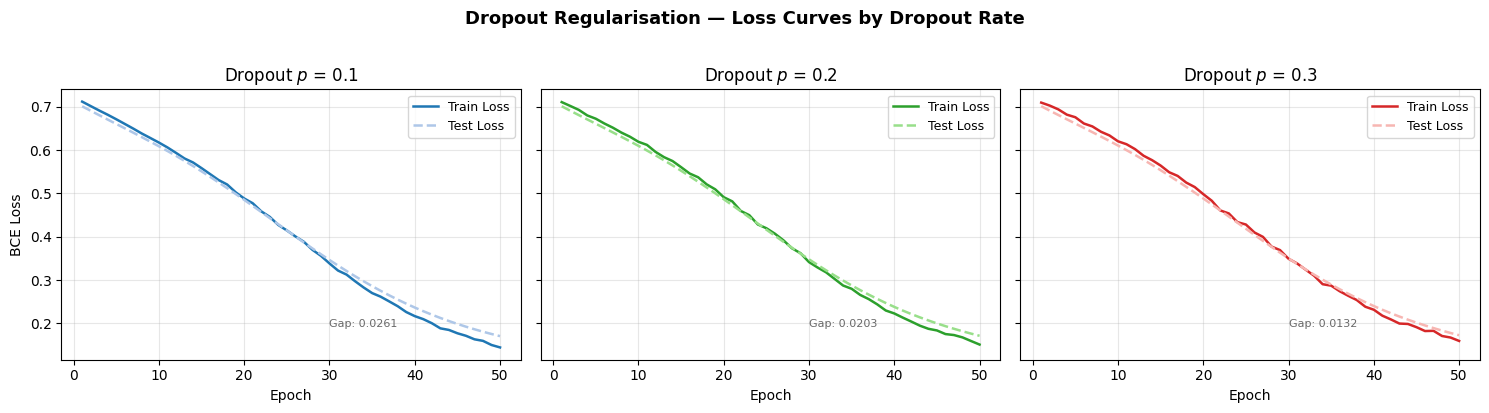

In [ ]:
# ── Combined Dropout Loss Curves ───────────────────────────────────────────────

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

dropout_rates = [0.1, 0.2, 0.3]
colours = {"train": ["#1f77b4", "#2ca02c", "#d62728"],
           "test":  ["#aec7e8", "#98df8a", "#f7b6b2"]}

num_epochs = 50
results = {}

for i, rate in enumerate(dropout_rates):
    set_seed(42)
    model_do = NetWithDropout(input_dim=X_train_tensor.shape[1], dropout_rate=rate)
    criterion_do = nn.BCELoss()
    optimizer_do = optim.Adam(model_do.parameters(), lr=0.001)

    train_l, test_l = [], []

    for epoch in range(num_epochs):
        model_do.train()
        optimizer_do.zero_grad()
        out = model_do(X_train_tensor)
        loss = criterion_do(out, y_train.unsqueeze(1))
        loss.backward()
        optimizer_do.step()
        train_l.append(loss.item())

        model_do.eval()
        with torch.no_grad():
            test_out  = model_do(X_test_tensor)
            test_loss = criterion_do(test_out, y_test.unsqueeze(1))
            test_l.append(test_loss.item())

    results[rate] = {"train": train_l, "test": test_l}

# ── Plot ───────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
epochs = range(1, num_epochs + 1)

for i, rate in enumerate(dropout_rates):
    ax = axes[i]
    ax.plot(epochs, results[rate]["train"],
            label="Train Loss", color=colours["train"][i], linewidth=1.8)
    ax.plot(epochs, results[rate]["test"],
            label="Test Loss",  color=colours["test"][i],
            linewidth=1.8, linestyle="--")
    ax.set_title(f"Dropout $p$ = {rate}", fontsize=12)
    ax.set_xlabel("Epoch")
    if i == 0:
        ax.set_ylabel("BCE Loss")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # annotate final gap
    final_gap = results[rate]["test"][-1] - results[rate]["train"][-1]
    ax.annotate(f"Gap: {final_gap:.4f}",
                xy=(num_epochs, results[rate]["test"][-1]),
                xytext=(num_epochs - 20, results[rate]["test"][-1] + 0.02),
                fontsize=8, color="dimgray")

fig.suptitle("Dropout Regularisation — Loss Curves by Dropout Rate",
             fontsize=13, fontweight="bold", y=1.02)

plt.tight_layout()
plt.savefig("dropout_curves.png", dpi=150, bbox_inches="tight")
plt.show()